运行约定：以本 Notebook 所在目录作为工作目录，从第一单元顺序运行。首个代码单元仅建立数据与输出目录。下面保存的输出与图来自课堂环境 `~/env_dl_uv` 内核的一次完整实跑（运行方式与成绩见下一段前言），不是未经验证的历史输出。


> **每个代码单元后面都跟着一个「预期输出」单元**：文字输出逐字摘录，图片导出到本目录 `assets/` 并以相对路径引用，因此执行 **Kernel → Clear All Outputs** 之后仍然看得见这次实跑的结果。
>
> 这里保存的输出来自 **课堂环境 `~/env_dl_uv`（Python 3.12.12 + PyTorch 2.14.1）的实跑**：Apple 芯片 MPS、`seed=42`、全量 MNIST、课堂默认 3 轮，端到端 37.22 s，最佳 test 准确率 **98.32%**（加载 checkpoint 复测同为 98.32%）。
>
> 与 `notebooks/` 里的课程 notebook 不同，本文件按开头写明的工作约定运行：**以 notebook 所在目录 `archive/` 为工作目录**，于是 `../data`、`../outputs` 落在 `01-image-classification/` 下，`assets/` 则是本目录（单图推理用的 `lenet-7.jpg` 就在这里）。
>
> 刷新方式（仓库根目录，先实跑、再内嵌）：
> - `uv run python english/scripts/execute_and_save.py --group vision --language zh-CN --cwd notebook --notebook 01-lenet-mnist-copy1`
> - `uv run python scripts/embed_expected_outputs.py --module 01-image-classification --include-archive --notebook 01-lenet-mnist-copy1`

In [1]:
import sys
from importlib.metadata import version
from IPython import get_ipython
get_ipython().run_line_magic("matplotlib", "inline")
assert sys.version_info[:2] == (3, 12), "请选择项目的 Python 3.12 内核。"
assert version('torch').split("+")[0] == '2.14.1', "请选择项目锁定的运行环境。"
print("Python：", sys.version.split()[0])
print('torch' + "：", version('torch'))
print("运行模式：", '课堂默认训练参数')

Python： 3.12.12
torch： 2.14.1
运行模式： 课堂默认训练参数


**预期输出：**

```text
Python： 3.12.12
torch： 2.14.1
运行模式： 课堂默认训练参数
```

In [2]:
from pathlib import Path
Path('../data').mkdir(parents=True, exist_ok=True)
Path('../outputs').mkdir(parents=True, exist_ok=True)


# LeNet-5 MNIST 手写数字识别分类器：教学规范版

本 Notebook 以经典 MNIST 手写数字识别为案例，完整走一遍深度学习图像分类项目的主线：

```text
问题定义 -> 数据理解 -> 图像预处理 -> 模型结构 -> 训练循环 -> 评估分析 -> 模型保存 -> 单图推理 -> 实验扩展
```

它不是单纯追求最高分，而是强调**教学清晰度、代码规范性、实验可复现性和工程可迁移性**。和传统机器学习 Titanic 案例相比，深度学习项目多了几个关键点：

- 输入不是表格特征，而是图像张量 `[N, C, H, W]`
- 特征不是手工设计，而是由卷积网络自动学习
- 训练过程不是一次 `fit()`，而是显式的 forward / loss / backward / step
- 评估不只看准确率，还要看混淆矩阵、错误样本和置信度
- 部署时要保证训练和推理的预处理完全一致

---

## 学习目标

完成本案例后，你应该能够：

1. 理解 MNIST 图像数据的基本结构和张量形状
2. 解释 LeNet-5 中卷积、池化、全连接层的作用
3. 写出规范的 PyTorch 训练循环和评估循环
4. 正确搭配 `logits + CrossEntropyLoss`
5. 保存和加载 `state_dict` / checkpoint
6. 对模型错误样本做基础分析
7. 将同样流程迁移到 CIFAR-10 或自定义图片分类任务

# 1. 项目设定与依赖导入

深度学习实验很容易受到随机初始化、数据打乱、设备差异影响。教学项目里建议先显式写清：

- 随机种子
- batch size / epoch / learning rate
- 数据目录和模型目录
- CPU / CUDA / Apple MPS 设备选择

这样学生在不同机器上运行时更容易定位问题。

In [3]:
from pathlib import Path
import random
import time

import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from PIL import Image, ImageOps
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import matplotlib.pyplot as plt


def set_seed(seed: int = 42):
    """尽量固定随机性，便于复现实验结果。"""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


SEED = 42
BATCH_SIZE = 64
TEST_BATCH_SIZE = 256
EPOCHS = 3
LEARNING_RATE = 1e-3
DATA_DIR = Path("../data")
MODEL_DIR = Path("../outputs/lenet_mnist_standard")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

set_seed(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "mps" if torch.backends.mps.is_available()
    else "cpu"
)

PIN_MEMORY = device.type == "cuda"
NUM_WORKERS = 0  # Notebook 环境中设为 0 更稳，脚本训练时可按机器配置调大。

print(f"Using device: {device}")
print(f"PyTorch version: {torch.__version__}")

Using device: mps
PyTorch version: 2.14.1


**预期输出：**

```text
Using device: mps
PyTorch version: 2.14.1
```

# 2. 数据准备

MNIST 是图像分类入门最常用的数据集：

| 项目 | 说明 |
| --- | --- |
| 任务类型 | 10 分类 |
| 类别 | 数字 0 到 9 |
| 训练集 | 60,000 张 |
| 测试集 | 10,000 张 |
| 原始尺寸 | 28 x 28 |
| 颜色通道 | 1 通道灰度图 |

LeNet-5 的经典输入尺寸是 `32x32`，因此这里把 MNIST 从 `28x28` resize 到 `32x32`。

训练集可以做轻量数据增强，但要符合业务语义。**不要对 MNIST 使用水平翻转**，因为翻转可能改变数字含义。这里使用小角度旋转、平移和轻微缩放。

In [4]:
MNIST_MEAN = (0.1307,)
MNIST_STD = (0.3081,)

train_transform = transforms.Compose([
    transforms.Resize((32, 32)),
    transforms.RandomAffine(
        degrees=10,
        translate=(0.08, 0.08),
        scale=(0.95, 1.05),
    ),
    transforms.ToTensor(),
    transforms.Normalize(MNIST_MEAN, MNIST_STD),
])

test_transform = transforms.Compose([
    transforms.Resize((32, 32)),
    transforms.ToTensor(),
    transforms.Normalize(MNIST_MEAN, MNIST_STD),
])

# 下载并加载 MNIST 数据集
#
# datasets.MNIST 关键参数说明：
# - root: 数据集保存目录。本项目统一保存到 ../data
# - train=True: 加载训练集，包含 60,000 张图片
# - train=False: 加载测试集，包含 10,000 张图片
# - download=True: 如果 root 下已经有 MNIST 数据，会直接复用本地文件；如果没有，会自动下载
# - transform: 读取图片时应用的预处理流程
#
# 如果课堂环境不能联网，可以先把 MNIST 数据复制到 ../data/MNIST/raw，
# 然后把 download 改成 False。
train_set = datasets.MNIST(
    root=DATA_DIR,          # 保存到当前目录下的 ../data 文件夹
    train=True,             # 加载训练集
    download=True,          # 本地不存在时自动下载，本地已存在时直接复用
    transform=train_transform,  # 应用训练集预处理和数据增强
)

test_set = datasets.MNIST(
    root=DATA_DIR,          # 同样保存到 ../data 文件夹
    train=False,            # 加载测试集
    download=True,          # 本地不存在时自动下载，本地已存在时直接复用
    transform=test_transform,   # 应用测试集预处理，不做随机增强
)

train_loader = DataLoader(
    train_set,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY,
)

test_loader = DataLoader(
    test_set,
    batch_size=TEST_BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY,
)

print(f"Train samples: {len(train_set)}")
print(f"Test samples:  {len(test_set)}")
print(f"Train batches: {len(train_loader)}")
print(f"Test batches:  {len(test_loader)}")

Train samples: 60000
Test samples:  10000
Train batches: 938
Test batches:  40


**预期输出：**

```text
Train samples: 60000
Test samples:  10000
Train batches: 938
Test batches:  40
```

# 3. 图像 EDA：理解数据而不是直接训练

表格项目会看缺失值、字段分布、相关性；图像项目也需要 EDA，只是关注点不同：

- 每个类别样本数是否均衡
- 图像尺寸和通道是否一致
- 像素值范围是否符合预期
- 标准化前后的图像是否还能正确显示
- 数据增强是否改变了类别语义

下面先看类别分布。MNIST 类别基本均衡，所以 accuracy 是一个可用的主指标。

/var/folders/4f/lx3tlt3d6fz2bys8ct46fzxh0000gn/T/ipykernel_97054/3607095927.py:1: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  targets = torch.tensor(train_set.targets)


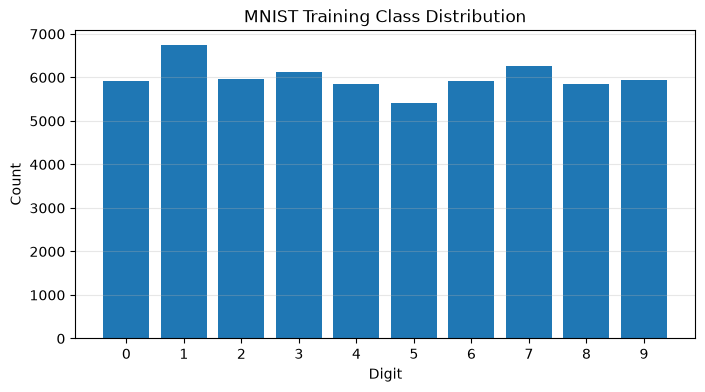

digit 0: 5923
digit 1: 6742
digit 2: 5958
digit 3: 6131
digit 4: 5842
digit 5: 5421
digit 6: 5918
digit 7: 6265
digit 8: 5851
digit 9: 5949


In [5]:
targets = torch.tensor(train_set.targets)
class_counts = torch.bincount(targets, minlength=10)

plt.figure(figsize=(8, 4))
plt.bar(range(10), class_counts.numpy())
plt.xticks(range(10))
plt.xlabel("Digit")
plt.ylabel("Count")
plt.title("MNIST Training Class Distribution")
plt.grid(axis="y", alpha=0.3)
plt.show()

for digit, count in enumerate(class_counts.tolist()):
    print(f"digit {digit}: {count}")

**预期输出：**

```text
…/3607095927.py:1: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  targets = torch.tensor(train_set.targets)
digit 0: 5923
digit 1: 6742
digit 2: 5958
digit 3: 6131
digit 4: 5842
digit 5: 5421
digit 6: 5918
digit 7: 6265
digit 8: 5851
digit 9: 5949
```

（输出里的 `…` 是 Jupyter 内核本次运行的临时目录，每台机器、每次运行都不同；告警本身可以忽略。）

**预期输出（图片）：**

![MNIST 训练集类别分布：10 个数字各自的样本数](assets/01-lenet-mnist-copy1-1.png)

*MNIST 训练集类别分布：10 个数字各自的样本数*

## 3.1 查看样本和张量形状

PyTorch 图像模型通常使用 `[N, C, H, W]`：

- `N`：batch size
- `C`：通道数，MNIST 是 1
- `H/W`：高度和宽度，这里是 32x32

理解这个形状非常关键，后续卷积层和全连接层的维度都依赖它。

Batch image shape: (64, 1, 32, 32)
Batch label shape: (64,)
Single image min/max after normalize: -0.4242129623889923 2.796030282974243


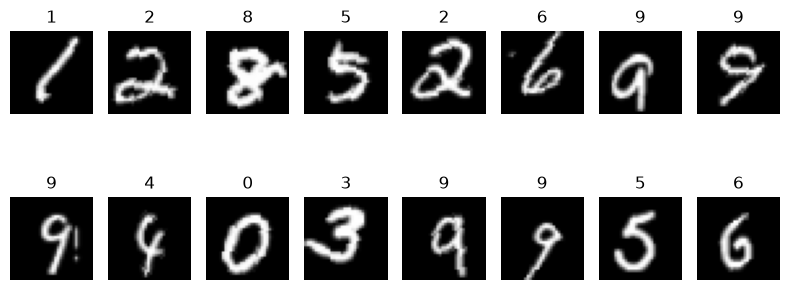

In [6]:
def denormalize(x: torch.Tensor) -> torch.Tensor:
    mean = torch.tensor(MNIST_MEAN).view(1, 1, 1)
    std = torch.tensor(MNIST_STD).view(1, 1, 1)
    return x.cpu() * std + mean

images, labels = next(iter(train_loader))
print("Batch image shape:", tuple(images.shape))
print("Batch label shape:", tuple(labels.shape))
print("Single image min/max after normalize:", float(images[0].min()), float(images[0].max()))

plt.figure(figsize=(8, 4))
for i in range(16):
    plt.subplot(2, 8, i + 1)
    plt.imshow(denormalize(images[i]).squeeze(), cmap="gray")
    plt.title(str(labels[i].item()))
    plt.axis("off")
plt.tight_layout()
plt.show()

**预期输出：**

```text
Batch image shape: (64, 1, 32, 32)
Batch label shape: (64,)
Single image min/max after normalize: -0.4242129623889923 2.796030282974243
```

**预期输出（图片）：**

![一个批次反归一化后的样本网格（标题是该图的标签）](assets/01-lenet-mnist-copy1-2.png)

*一个批次反归一化后的样本网格（标题是该图的标签）*

# 4. LeNet-5 模型结构

LeNet-5 是早期卷积神经网络的代表结构，非常适合教学：

```text
Input 1x32x32
  -> Conv(1->6, 5x5) + ReLU        => 6x28x28
  -> MaxPool(2x2)                  => 6x14x14
  -> Conv(6->16, 5x5) + ReLU       => 16x10x10
  -> MaxPool(2x2)                  => 16x5x5
  -> Flatten                       => 400
  -> FC 400->120 -> 84 -> 10
```

注意：模型最后一层输出的是 10 个原始分数，也就是 logits。训练时使用 `CrossEntropyLoss`，它内部会完成 `log_softmax + NLLLoss`，因此模型里不要再手动写 `softmax`。

In [7]:
class LeNet5(nn.Module):
    def __init__(self, num_classes: int = 10):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 6, kernel_size=5),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2),
            nn.Conv2d(6, 16, kernel_size=5),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2),
        )
        self.classifier = nn.Sequential(
            nn.Linear(16 * 5 * 5, 120),
            nn.ReLU(inplace=True),
            nn.Linear(120, 84),
            nn.ReLU(inplace=True),
            nn.Linear(84, num_classes),
        )

    def forward(self, x):
        x = self.features(x)
        x = torch.flatten(x, 1)
        return self.classifier(x)


model = LeNet5().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print(model)
print(f"Total params: {total_params:,}")
print(f"Trainable params: {trainable_params:,}")

LeNet5(
  (features): Sequential(
    (0): Conv2d(1, 6, kernel_size=(5, 5), stride=(1, 1))
    (1): ReLU(inplace=True)
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(6, 16, kernel_size=(5, 5), stride=(1, 1))
    (4): ReLU(inplace=True)
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Linear(in_features=400, out_features=120, bias=True)
    (1): ReLU(inplace=True)
    (2): Linear(in_features=120, out_features=84, bias=True)
    (3): ReLU(inplace=True)
    (4): Linear(in_features=84, out_features=10, bias=True)
  )
)
Total params: 61,706
Trainable params: 61,706


**预期输出：**

```text
LeNet5(
  (features): Sequential(
    (0): Conv2d(1, 6, kernel_size=(5, 5), stride=(1, 1))
    (1): ReLU(inplace=True)
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(6, 16, kernel_size=(5, 5), stride=(1, 1))
    (4): ReLU(inplace=True)
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Linear(in_features=400, out_features=120, bias=True)
    (1): ReLU(inplace=True)
    (2): Linear(in_features=120, out_features=84, bias=True)
    (3): ReLU(inplace=True)
    (4): Linear(in_features=84, out_features=10, bias=True)
  )
)
Total params: 61,706
Trainable params: 61,706
```

## 4.1 用一次前向传播检查维度

正式训练前，建议先用一个 batch 跑一次 forward：

- 确认输入形状正确
- 确认输出形状是 `[batch_size, num_classes]`
- 确认 loss 可以正常计算

这一步能提前发现大部分维度错误。

In [8]:
sample_images, sample_labels = next(iter(train_loader))
sample_images = sample_images.to(device)
sample_labels = sample_labels.to(device)

with torch.no_grad():
    sample_logits = model(sample_images)
    sample_loss = criterion(sample_logits, sample_labels)

print("Input shape:", tuple(sample_images.shape))
print("Logits shape:", tuple(sample_logits.shape))
print("Sample loss:", float(sample_loss))
print("Predicted classes shape:", tuple(sample_logits.argmax(dim=1).shape))

Input shape: (64, 1, 32, 32)
Logits shape: (64, 10)
Sample loss: 2.3046483993530273
Predicted classes shape: (64,)


**预期输出：**

```text
Input shape: (64, 1, 32, 32)
Logits shape: (64, 10)
Sample loss: 2.3046483993530273
Predicted classes shape: (64,)
```

# 5. 训练循环：深度学习项目的核心

和 sklearn 的 `model.fit()` 不同，PyTorch 通常显式写训练循环：

1. `model.train()`：进入训练模式
2. forward：计算 logits
3. loss：计算损失
4. `loss.backward()`：反向传播
5. `optimizer.step()`：更新参数
6. 统计 epoch 平均 loss 和 accuracy

评估阶段要使用 `model.eval()` 和 `torch.no_grad()`，避免 Dropout/BatchNorm 行为错误，也避免无意义的梯度计算。

In [9]:
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad(set_to_none=True)
        logits = model(images)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()

        batch_size = labels.size(0)
        running_loss += loss.item() * batch_size
        preds = logits.argmax(dim=1)
        correct += (preds == labels).sum().item()
        total += batch_size

    return running_loss / total, correct / total


@torch.no_grad()
def evaluate(model, loader, criterion, device):
    model.eval()
    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)

        logits = model(images)
        loss = criterion(logits, labels)

        batch_size = labels.size(0)
        running_loss += loss.item() * batch_size
        preds = logits.argmax(dim=1)
        correct += (preds == labels).sum().item()
        total += batch_size

    return running_loss / total, correct / total

# 6. 训练模型并保存最佳 checkpoint

这里保存两种文件：

| 文件 | 用途 |
| --- | --- |
| `best_lenet5_mnist_state_dict.pth` | 只保存模型参数，适合部署推理 |
| `best_lenet5_mnist_checkpoint.pth` | 保存模型参数、优化器、epoch、history，适合恢复训练 |

教学时建议优先讲 `state_dict`，因为它更稳定、更符合 PyTorch 推荐方式。

In [10]:
history = {
    "train_loss": [],
    "train_acc": [],
    "test_loss": [],
    "test_acc": [],
}

best_acc = 0.0
best_path = MODEL_DIR / "best_lenet5_mnist_state_dict.pth"
checkpoint_path = MODEL_DIR / "best_lenet5_mnist_checkpoint.pth"

for epoch in range(1, EPOCHS + 1):
    start = time.time()

    train_loss, train_acc = train_one_epoch(model, train_loader, criterion, optimizer, device)
    test_loss, test_acc = evaluate(model, test_loader, criterion, device)

    history["train_loss"].append(train_loss)
    history["train_acc"].append(train_acc)
    history["test_loss"].append(test_loss)
    history["test_acc"].append(test_acc)

    if test_acc > best_acc:
        best_acc = test_acc
        torch.save(model.state_dict(), best_path)
        torch.save({
            "epoch": epoch,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "best_acc": best_acc,
            "history": history,
            "config": {
                "seed": SEED,
                "batch_size": BATCH_SIZE,
                "test_batch_size": TEST_BATCH_SIZE,
                "epochs": EPOCHS,
                "learning_rate": LEARNING_RATE,
                "mnist_mean": MNIST_MEAN,
                "mnist_std": MNIST_STD,
            },
        }, checkpoint_path)

    elapsed = time.time() - start
    print(
        f"Epoch {epoch:02d}/{EPOCHS} | "
        f"train_loss={train_loss:.4f}, train_acc={train_acc*100:.2f}% | "
        f"test_loss={test_loss:.4f}, test_acc={test_acc*100:.2f}% | "
        f"time={elapsed:.1f}s"
    )

print(f"Best test accuracy: {best_acc*100:.2f}%")
print(f"Best state_dict saved to: {best_path}")
print(f"Best checkpoint saved to: {checkpoint_path}")

Epoch 01/3 | train_loss=0.3399, train_acc=89.31% | test_loss=0.0634, test_acc=98.08% | time=11.0s


Epoch 02/3 | train_loss=0.1143, train_acc=96.43% | test_loss=0.0506, test_acc=98.32% | time=10.1s


Epoch 03/3 | train_loss=0.0867, train_acc=97.34% | test_loss=0.0503, test_acc=98.32% | time=10.1s
Best test accuracy: 98.32%
Best state_dict saved to: ../outputs/lenet_mnist_standard/best_lenet5_mnist_state_dict.pth
Best checkpoint saved to: ../outputs/lenet_mnist_standard/best_lenet5_mnist_checkpoint.pth


**预期输出：**

```text
Epoch 01/3 | train_loss=0.3399, train_acc=89.31% | test_loss=0.0634, test_acc=98.08% | time=11.0s
Epoch 02/3 | train_loss=0.1143, train_acc=96.43% | test_loss=0.0506, test_acc=98.32% | time=10.1s
Epoch 03/3 | train_loss=0.0867, train_acc=97.34% | test_loss=0.0503, test_acc=98.32% | time=10.1s
Best test accuracy: 98.32%
Best state_dict saved to: ../outputs/lenet_mnist_standard/best_lenet5_mnist_state_dict.pth
Best checkpoint saved to: ../outputs/lenet_mnist_standard/best_lenet5_mnist_checkpoint.pth
```

# 7. 训练过程可视化

训练曲线可以帮助判断模型状态：

- train loss 和 test loss 都下降：正常学习
- train loss 下降但 test loss 上升：可能过拟合
- loss 几乎不变：学习率、模型结构或数据预处理可能有问题
- train/test accuracy 差距很大：泛化能力不足

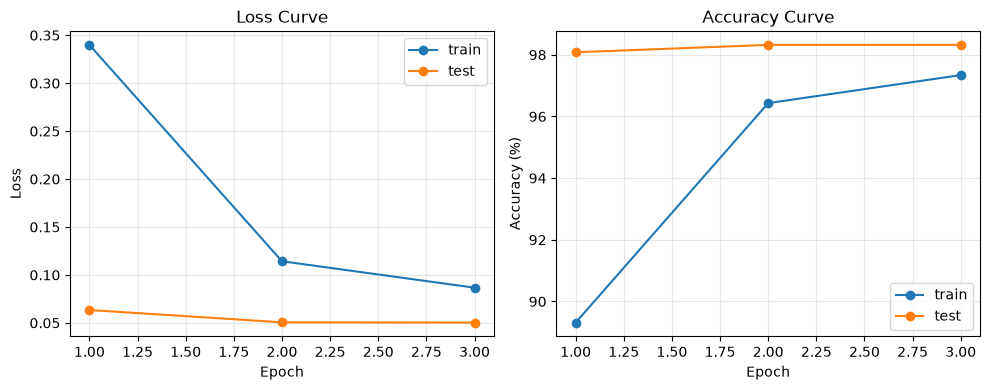

In [11]:
epochs = range(1, len(history["train_loss"]) + 1)

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(epochs, history["train_loss"], marker="o", label="train")
plt.plot(epochs, history["test_loss"], marker="o", label="test")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Loss Curve")
plt.grid(alpha=0.3)
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(epochs, [v * 100 for v in history["train_acc"]], marker="o", label="train")
plt.plot(epochs, [v * 100 for v in history["test_acc"]], marker="o", label="test")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("Accuracy Curve")
plt.grid(alpha=0.3)
plt.legend()

plt.tight_layout()
plt.show()

**预期输出（图片）：**

![本次 3 轮训练的 loss 与 accuracy 曲线，train 与 test 同图对比](assets/01-lenet-mnist-copy1-3.png)

*本次 3 轮训练的 loss 与 accuracy 曲线，train 与 test 同图对比*

# 8. 模型评估：混淆矩阵与错误样本

accuracy 只告诉我们总体表现，不告诉我们“错在哪里”。图像分类教学中，建议至少补充两类分析：

1. 混淆矩阵：哪些数字之间最容易混淆
2. 错误样本：模型错判时，图片本身是否模糊、歪斜或标注难辨

下面不依赖 sklearn，直接用 PyTorch 统计混淆矩阵。

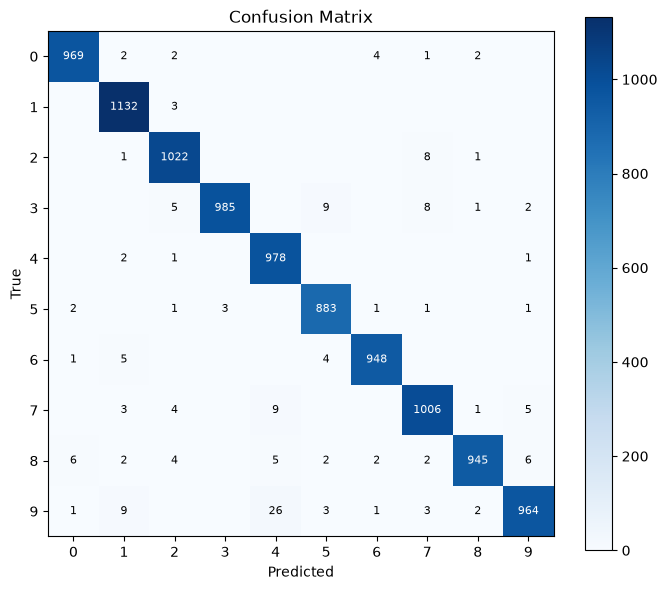

digit 0: 98.88%
digit 1: 99.74%
digit 2: 99.03%
digit 3: 97.52%
digit 4: 99.59%
digit 5: 98.99%
digit 6: 98.96%
digit 7: 97.86%
digit 8: 97.02%
digit 9: 95.54%


In [12]:
best_model = LeNet5().to(device)
best_model.load_state_dict(torch.load(best_path, map_location=device))
best_model.eval()

num_classes = 10
confusion = torch.zeros(num_classes, num_classes, dtype=torch.int64)
wrong_examples = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)
        logits = best_model(images)
        probs = torch.softmax(logits, dim=1)
        preds = logits.argmax(dim=1)

        for true_label, pred_label in zip(labels.cpu(), preds.cpu()):
            confusion[true_label, pred_label] += 1

        wrong_mask = preds != labels
        if wrong_mask.any() and len(wrong_examples) < 24:
            wrong_images = images[wrong_mask].cpu()
            wrong_labels = labels[wrong_mask].cpu()
            wrong_preds = preds[wrong_mask].cpu()
            wrong_probs = probs[wrong_mask].cpu()
            for img, true_label, pred_label, prob in zip(wrong_images, wrong_labels, wrong_preds, wrong_probs):
                wrong_examples.append((img, int(true_label), int(pred_label), float(prob[pred_label])))
                if len(wrong_examples) >= 24:
                    break

plt.figure(figsize=(7, 6))
plt.imshow(confusion.numpy(), cmap="Blues")
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.xticks(range(10))
plt.yticks(range(10))
plt.colorbar()

for i in range(10):
    for j in range(10):
        value = int(confusion[i, j])
        if value > 0:
            color = "white" if value > confusion.max() * 0.5 else "black"
            plt.text(j, i, str(value), ha="center", va="center", color=color, fontsize=8)

plt.tight_layout()
plt.show()

class_accuracy = confusion.diag() / confusion.sum(dim=1).clamp(min=1)
for digit, acc in enumerate(class_accuracy.tolist()):
    print(f"digit {digit}: {acc*100:.2f}%")

**预期输出：**

```text
digit 0: 98.88%
digit 1: 99.74%
digit 2: 99.03%
digit 3: 97.52%
digit 4: 99.59%
digit 5: 98.99%
digit 6: 98.96%
digit 7: 97.86%
digit 8: 97.02%
digit 9: 95.54%
```

**预期输出（图片）：**

![test 集混淆矩阵：横轴为预测类别，纵轴为真实类别](assets/01-lenet-mnist-copy1-4.png)

*test 集混淆矩阵：横轴为预测类别，纵轴为真实类别*

## 8.1 查看错误样本

错误样本分析是非常有教学价值的一步。它能帮助学生理解：模型不是“凭空犯错”，错误往往来自图像模糊、书写风格特殊、类别边界本身不清晰。

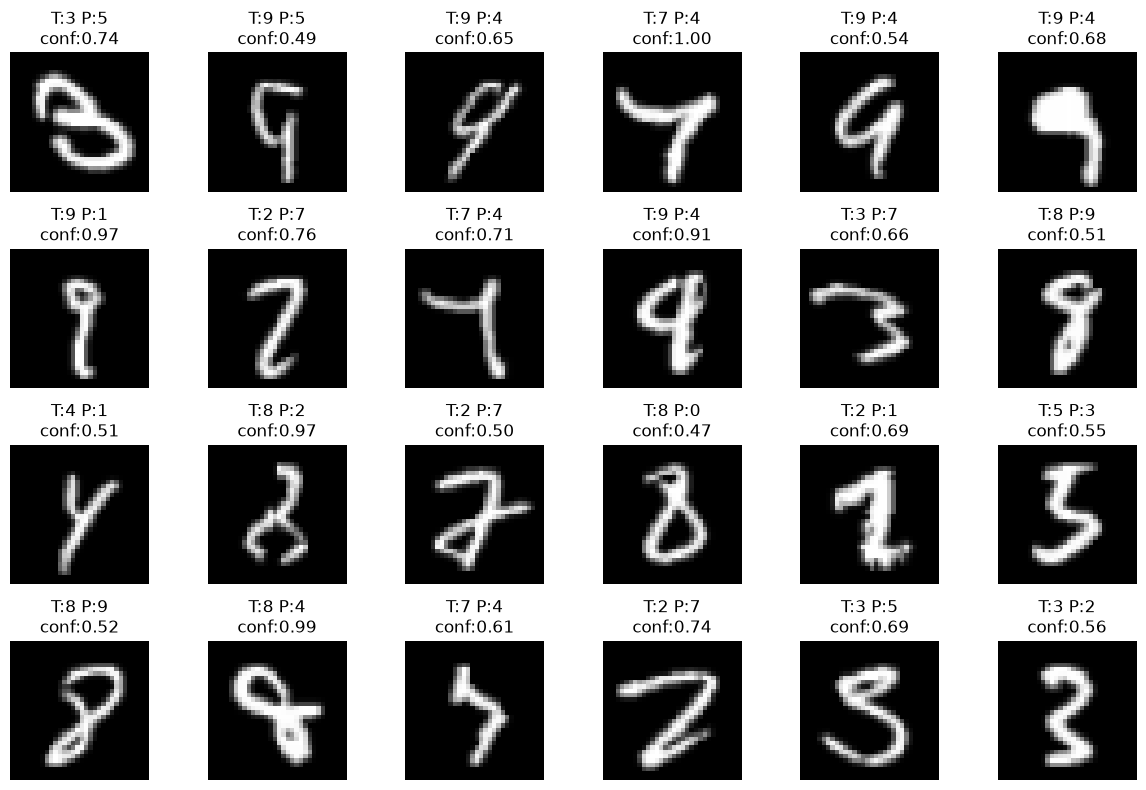

In [13]:
if wrong_examples:
    cols = 6
    rows = int(np.ceil(len(wrong_examples) / cols))
    plt.figure(figsize=(12, 2 * rows))

    for idx, (img, true_label, pred_label, confidence) in enumerate(wrong_examples):
        plt.subplot(rows, cols, idx + 1)
        plt.imshow(denormalize(img).squeeze(), cmap="gray")
        plt.title(f"T:{true_label} P:{pred_label}\nconf:{confidence:.2f}")
        plt.axis("off")

    plt.tight_layout()
    plt.show()
else:
    print("No wrong examples collected.")

**预期输出（图片）：**

![收集到的错误样本：标题依次是真值 T、预测 P 与置信度](assets/01-lenet-mnist-copy1-5.png)

*收集到的错误样本：标题依次是真值 T、预测 P 与置信度*

# 9. 保存、加载与部署视角

训练结束后，推荐的推理加载方式是：

1. 重新创建模型结构 `LeNet5()`
2. 加载 `state_dict`
3. `model.eval()`
4. 使用和测试集一致的预处理

这比直接 `torch.save(model)` 更稳定，因为它不依赖保存时的 Python 类路径。

In [14]:
loaded_model = LeNet5().to(device)
loaded_model.load_state_dict(torch.load(best_path, map_location=device))
loaded_model.eval()

loaded_loss, loaded_accuracy = evaluate(loaded_model, test_loader, criterion, device)
print(f"Loaded model test loss: {loaded_loss:.4f}")
print(f"Loaded model test accuracy: {loaded_accuracy*100:.2f}%")

Loaded model test loss: 0.0506
Loaded model test accuracy: 98.32%


**预期输出：**

```text
Loaded model test loss: 0.0506
Loaded model test accuracy: 98.32%
```

# 10. 单张图片推理

外部图片与 MNIST 数据常有差异：

- MNIST 是黑底亮字
- 拍照或截图可能是白底黑字
- 图片大小、边距、笔画粗细都可能不同

下面的函数默认根据平均亮度自动判断是否需要反色，然后复用测试集预处理。这样可以减少训练和部署之间的预处理不一致。

Prediction: 5
Confidence: 0.9959
Probabilities: [0.000e+00 0.000e+00 0.000e+00 8.000e-04 0.000e+00 9.959e-01 0.000e+00
 0.000e+00 0.000e+00 3.200e-03]


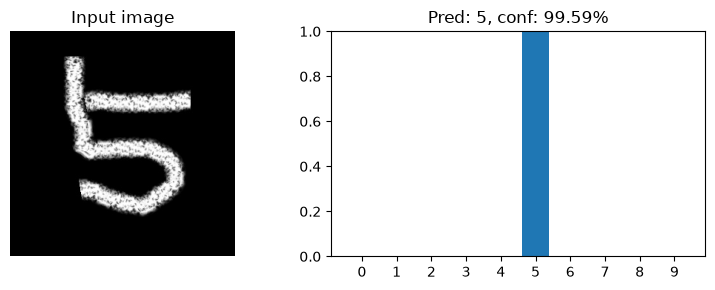

In [15]:
def load_digit_image(image_path, auto_invert=True):
    image = Image.open(image_path).convert("L")

    if auto_invert and np.asarray(image).mean() > 127:
        image = ImageOps.invert(image)

    return test_transform(image).unsqueeze(0), image


@torch.no_grad()
def predict_digit(model, image_path, device, auto_invert=True):
    model.eval()
    image_tensor, raw_image = load_digit_image(image_path, auto_invert=auto_invert)
    image_tensor = image_tensor.to(device)
    logits = model(image_tensor)
    probabilities = torch.softmax(logits, dim=1).squeeze(0).cpu()
    pred = int(probabilities.argmax().item())
    confidence = float(probabilities[pred].item())
    return pred, confidence, probabilities, raw_image


image_path = Path("assets/lenet-7.jpg")
if image_path.exists():
    pred, confidence, probabilities, raw_image = predict_digit(loaded_model, image_path, device)
    print(f"Prediction: {pred}")
    print(f"Confidence: {confidence:.4f}")
    print("Probabilities:", probabilities.numpy().round(4))

    plt.figure(figsize=(8, 3))
    plt.subplot(1, 2, 1)
    plt.imshow(raw_image, cmap="gray")
    plt.title("Input image")
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.bar(range(10), probabilities.numpy())
    plt.xticks(range(10))
    plt.ylim(0, 1)
    plt.title(f"Pred: {pred}, conf: {confidence:.2%}")
    plt.tight_layout()
    plt.show()
else:
    print(f"Image not found: {image_path}")

**预期输出：**

```text
Prediction: 5
Confidence: 0.9959
Probabilities: [0.000e+00 0.000e+00 0.000e+00 8.000e-04 0.000e+00 9.959e-01 0.000e+00
 0.000e+00 0.000e+00 3.200e-03]
```

**预期输出（图片）：**

![单图推理 `assets/lenet-7.jpg`：预测 5，置信度 0.9959](assets/01-lenet-mnist-copy1-6.png)

*单图推理 `assets/lenet-7.jpg`：预测 5，置信度 0.9959*

# 11. 实验扩展建议

教学时可以把这个 notebook 作为主线，然后安排几个渐进实验：

| 实验 | 修改点 | 观察目标 |
| --- | --- | --- |
| 去掉数据增强 | 删除 `RandomAffine` | 看测试集准确率和错误样本变化 |
| 调整 epoch | `EPOCHS = 1 / 3 / 5` | 理解训练轮数和收敛 |
| 调整学习率 | `1e-2 / 1e-3 / 1e-4` | 观察 loss 曲线是否震荡或过慢 |
| 换优化器 | Adam -> SGD | 比较优化器差异 |
| 加 Dropout | FC 层加入 Dropout | 理解正则化 |
| 迁移 CIFAR-10 | 输入通道 1 -> 3 | 理解彩色图像和更难任务 |

---

# 12. 项目总结

本项目完整覆盖了一个规范图像分类任务的核心流程：

```text
数据集加载
  -> 图像 EDA
  -> transform 预处理
  -> DataLoader 批量加载
  -> LeNet-5 模型定义
  -> logits + CrossEntropyLoss
  -> train/evaluate 循环
  -> checkpoint 保存
  -> 混淆矩阵和错误样本分析
  -> 单图推理
```

和表格机器学习项目相比，深度学习项目更强调：

- 张量形状
- 训练循环
- GPU/CPU 设备管理
- 数据增强
- 模型参数保存
- 推理预处理一致性

这个版本适合作为课堂教学主 notebook；原始 notebook 中的“简版”和“炫酷版”可以作为对照材料，而正式讲解建议围绕本规范版展开。